# TP — Analyse en Composantes Principales (ACPN)
## Données : Indicateurs socio-économiques de 167 pays
**Source : Banque Mondiale / Kaggle**

| Variable | Description |
|---|---|
| `mortalite_infantile` | Mortalité infantile (pour 1000 naissances) |
| `exportations` | Exportations (% du PIB) |
| `depenses_sante` | Dépenses de santé (% du PIB) |
| `importations` | Importations (% du PIB) |
| `revenu` | Revenu moyen par habitant (USD) |
| `inflation` | Taux d'inflation annuel (%) |
| `esperance_vie` | Espérance de vie (années) |
| `fecondite` | Taux de fécondité (enfants/femme) |
| `pib_habitant` | PIB par habitant (USD) |

## Imports

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Etape 0 — Chargement des données

In [39]:
df = pd.read_csv('donnees_pays.csv')

# Supprimer les valeurs manquantes
df = df.dropna()

print(f"Nombre de pays    : {len(df)}") # Afficher le nombre de pays
print(f"Nombre de variables : {df.shape[1] - 1}") # Afficher le nombre de variables
df.head(10) # Afficher les 10 premières lignes du DataFrame

Nombre de pays    : 169
Nombre de variables : 9


,pays,mortalite_infantile,exportations,depenses_sante,importations,revenu,inflation,esperance_vie,fecondite,pib_habitant
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553.0
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090.0
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460.0
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530.0
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200.0
5,Argentina,14.5,18.9,8.10,16.0,18700,20.90,75.8,2.37,10300.0
6,Armenia,18.1,20.8,4.40,45.3,6700,7.77,73.3,1.69,3220.0
7,Australia,4.8,19.8,8.73,20.9,41400,1.16,82.0,1.93,51900.0
8,Austria,4.3,51.3,11.00,47.8,43200,0.87,80.5,1.44,46900.0
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.80,69.1,1.92,5840.0


## Etape 1 — Centrage et réduction

**Formule :**
$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{\sigma_j}$$

In [40]:
# On garde uniquement les colonnes numériques
numeric_cols = df.select_dtypes(include=[np.number]).columns
Xcr = df[numeric_cols]

# Calcul des moyennes
moyennes = Xcr.mean()
print("Moyennes :")
print(moyennes.round(4))

Moyennes :
mortalite_infantile       34.3148
exportations              42.7176
depenses_sante             6.7755
importations              46.1006
revenu                 16779.0710
inflation                  6.4264
esperance_vie             70.2385
fecondite                  2.9135
pib_habitant           13302.3136
dtype: float64


In [41]:
# Calcul des écarts-types 
ecarts_types = Xcr.std()
print("Ecarts-types :")
print(ecarts_types.round(4))

Ecarts-types :
mortalite_infantile       33.6025
exportations              27.7894
depenses_sante             2.6869
importations              23.9279
revenu                 19017.2746
inflation                 10.5143
esperance_vie              8.8823
fecondite                  1.4773
pib_habitant           19029.9531
dtype: float64


In [42]:
# Centrage et réduction
Xcr = (Xcr - moyennes) / ecarts_types

print("Matrice centrée-réduite (10 premiers pays) :")
Xcr.head(10)

Matrice centrée-réduite (10 premiers pays) :


,mortalite_infantile,exportations,depenses_sante,importations,revenu,inflation,esperance_vie,fecondite,pib_habitant
0,1.663128,-1.177343,0.299416,-0.050175,-0.797647,0.286615,-1.580501,1.967440,-0.669960
1,-0.527187,-0.529613,-0.083927,0.104456,-0.360150,-0.184173,0.682430,-0.855268,-0.484095
2,-0.208758,-0.155370,-0.969712,-0.614371,-0.203976,0.920039,0.704947,-0.015901,-0.464652
3,2.520208,0.704671,-1.460987,-0.133760,-0.572063,1.519223,-1.141425,2.197589,-0.513523
4,-0.714674,0.100123,-0.277460,0.534916,0.122043,-0.474255,0.738722,-0.530352,-0.057925
5,-0.589683,-0.857077,0.492949,-1.257971,0.101010,1.376560,0.626138,-0.367894,-0.157768
6,-0.482548,-0.788705,-0.884111,-0.033459,-0.529996,0.127783,0.344679,-0.828191,-0.529813
7,-0.878352,-0.824690,0.727421,-1.053189,1.294661,-0.500885,1.324157,-0.665733,2.028260
8,-0.893232,0.308836,1.572266,0.071022,1.389312,-0.528467,1.155281,-0.997418,1.765516
9,0.145382,0.416791,-0.333287,-1.061548,-0.040966,0.701289,-0.128172,-0.672502,-0.392135


## Etape 2 — Matrice de corrélation R

**Formule :**
$$R = \frac{1}{n} Z^T Z$$

In [43]:
# Calcul de la matrice de corrélation
n = len(Xcr)
R = (1/n) * Xcr.T.dot(Xcr)

print("Matrice de corrélation R :")
print(R.round(1))

Matrice de corrélation R :
                     mortalite_infantile  exportations  depenses_sante  \
mortalite_infantile                  1.0          -0.3            -0.3   
exportations                        -0.3           1.0            -0.0   
depenses_sante                      -0.3          -0.0             1.0   
importations                        -0.2           0.7             0.2   
revenu                              -0.5           0.5             0.2   
inflation                            0.2          -0.1            -0.1   
esperance_vie                       -0.9           0.3             0.3   
fecondite                            0.9          -0.3            -0.3   
pib_habitant                        -0.5           0.4             0.3   

                     importations  revenu  inflation  esperance_vie  \
mortalite_infantile          -0.2    -0.5        0.2           -0.9   
exportations                  0.7     0.5       -0.1            0.3   
depenses_sante     

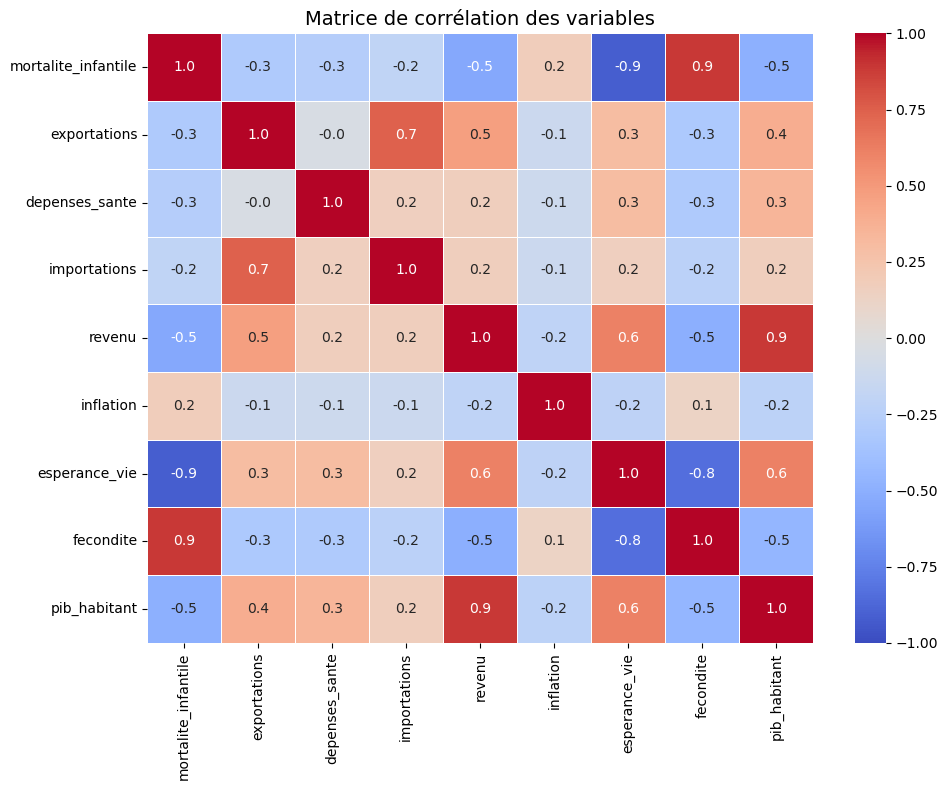

In [44]:

plt.figure(figsize=(10, 8))
sns.heatmap(R, annot=True, fmt=".1f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1,
            linewidths=0.5)
plt.title("Matrice de corrélation des variables", fontsize=14)
plt.tight_layout()
plt.show()

**Interprétation de la matrice de corrélation**

La mortalité infantile est fortement liée à la fécondité (corrélation positive, environ 0,9) et opposée à l'espérance de vie (environ -0,9). Le revenu et le PIB par habitant évoluent fortement ensemble (environ 0,9), tout comme les exportations et les importations (environ 0,7). Ces associations montrent des liens entre indicateurs, sans établir de causalité.


## Etape 3 — Valeurs propres et vecteurs propres

**Formule :**
$$\det(R - \lambda I) = 0$$

In [45]:
# Calcul des valeurs et vecteurs propres
valeurs_propres, vecteurs_propres = np.linalg.eigh(R)

# Tri par ordre décroissant
# Parce que les valeurs propres représentent la variance expliquée par chaque composante principale. 
# En les triant par ordre décroissant, on peut identifier les composantes les plus importantes qui expliquent le plus de variance dans les données. 
# Cela permet de réduire la dimensionnalité tout en conservant l'essentiel de l'information.
idx = np.argsort(valeurs_propres)[::-1]
valeurs_propres = valeurs_propres[idx]
vecteurs_propres = vecteurs_propres[:, idx]

# Affichage
print("Valeurs propres (λ) :")
for i, lam in enumerate(valeurs_propres):
    pct     = (lam / np.sum(valeurs_propres)) * 100
    pct_cum = np.sum(valeurs_propres[:i+1]) / np.sum(valeurs_propres) * 100
    print(f"  λ{i+1} = {lam:.4f}  →  Inertie : {pct:.2f}%  (cumulé : {pct_cum:.2f}%)")

Valeurs propres (λ) :
  λ1 = 4.2270  →  Inertie : 47.25%  (cumulé : 47.25%)
  λ2 = 1.4860  →  Inertie : 16.61%  (cumulé : 63.86%)
  λ3 = 0.9986  →  Inertie : 11.16%  (cumulé : 75.02%)
  λ4 = 0.9510  →  Inertie : 10.63%  (cumulé : 85.65%)
  λ5 = 0.8523  →  Inertie : 9.53%  (cumulé : 95.17%)
  λ6 = 0.1528  →  Inertie : 1.71%  (cumulé : 96.88%)
  λ7 = 0.1388  →  Inertie : 1.55%  (cumulé : 98.43%)
  λ8 = 0.0857  →  Inertie : 0.96%  (cumulé : 99.39%)
  λ9 = 0.0546  →  Inertie : 0.61%  (cumulé : 100.00%)


In [46]:
# Vecteurs propres unitaires
vp_df = pd.DataFrame(
    vecteurs_propres,
    index=numeric_cols,
    columns=[f"v{i+1}" for i in range(len(valeurs_propres))]
)
print("Vecteurs propres unitaires :")
print(vp_df.round(4))

Vecteurs propres unitaires :
                         v1      v2      v3      v4      v5      v6      v7  \
mortalite_infantile -0.4210  0.2087 -0.3021 -0.0553 -0.2219  0.2116  0.0701   
exportations         0.2729  0.6295  0.0868 -0.1064 -0.0154  0.3358 -0.6271   
depenses_sante       0.1866 -0.2136 -0.2284  0.7208 -0.5100  0.1552 -0.2013   
importations         0.1950  0.6528  0.1372  0.3619 -0.0488 -0.3599  0.4990   
revenu               0.3909  0.0152 -0.2774 -0.4362 -0.2178  0.1858  0.2731   
inflation           -0.1447 -0.0547  0.6771 -0.2331 -0.6773 -0.0647 -0.0042   
esperance_vie        0.4342 -0.2271  0.1713 -0.0032  0.1566 -0.4781 -0.3244   
fecondite           -0.4067  0.1800 -0.3501 -0.1131 -0.1755 -0.6112 -0.3557   
pib_habitant         0.3845 -0.0349 -0.3781 -0.2786 -0.3557 -0.2192  0.0771   

                         v8      v9  
mortalite_infantile -0.3924 -0.6573  
exportations        -0.0292  0.0580  
depenses_sante       0.1489 -0.0311  
importations         0.0188 

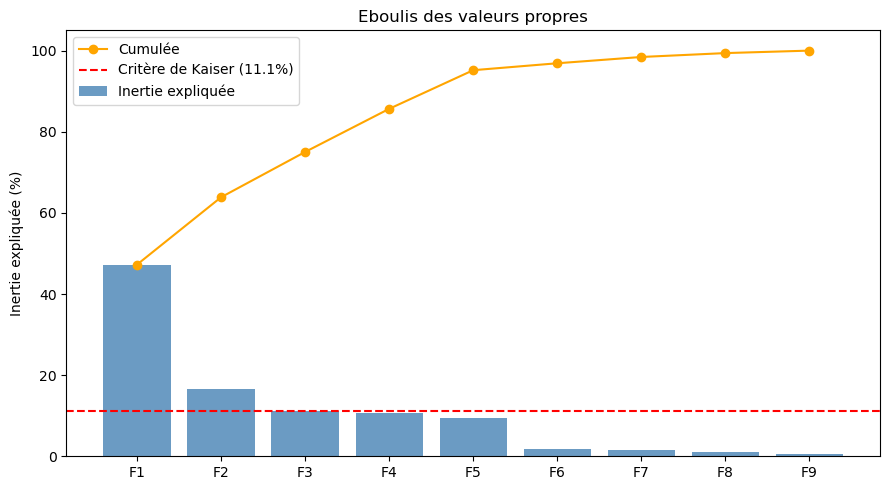

In [47]:
# Eboulis des valeurs propres
pct_expliquee = valeurs_propres / np.sum(valeurs_propres) * 100
pct_cumulee   = np.cumsum(pct_expliquee)
axes_labels   = [f"F{i+1}" for i in range(len(valeurs_propres))]

plt.figure(figsize=(9, 5))
plt.bar(axes_labels, pct_expliquee, color="steelblue", alpha=0.8, label="Inertie expliquée")
plt.plot(axes_labels, pct_cumulee, color="orange", marker="o", label="Cumulée")
plt.axhline(y=100/len(numeric_cols), color="red", linestyle="--",
            label=f"Critère de Kaiser ({100/len(numeric_cols):.1f}%)")
plt.title("Eboulis des valeurs propres")
plt.ylabel("Inertie expliquée (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Interprétation de l'éboulis des valeurs propres**

F1 explique 47,25 % de l'inertie et F2 16,61 %, soit 63,86 % cumulés : le plan F1 × F2 résume donc une part importante, mais pas toute l'information. Les deux premiers axes dépassent le seuil de Kaiser (environ 11,1 % par axe) et sont les plus pertinents à interpréter.


## Etape 4 — Axes factoriels et composantes principales

**Formule :**
$$F_k = Z \cdot v_k$$

In [48]:
# Calcul des composantes principales
composantes = Xcr.values @ vecteurs_propres
composantes_df = pd.DataFrame(
    composantes,
    index=df["pays"].values,
    columns=[f"F{i+1}" for i in range(composantes.shape[1])]
)

print("Composantes principales (10 premiers pays) :")
composantes_df.head(10)

Composantes principales (10 premiers pays) :


,F1,F2,F3,F4,F5,F6,F7,F8,F9
Afghanistan,-3.072567,0.217889,-0.970759,0.481387,-0.875954,-0.445527,0.311658,0.231407,-0.040262
Albania,0.426033,-0.644715,0.721302,0.492214,0.795201,-0.092472,0.312158,-0.109048,-0.248192
Algeria,-0.334190,-0.535437,1.168299,-0.889831,0.272934,-0.348596,-0.346984,-0.004182,-0.339365
Angola,-3.197545,1.775222,0.031844,-1.522200,-1.104699,-0.298005,-0.651612,-0.340499,-0.698653
Antigua and Barbuda,1.011242,0.088926,0.340469,0.153490,0.796397,-0.316206,0.189833,0.070425,-0.093947
Argentina,0.062147,-1.865730,1.018303,-0.257626,-0.781534,0.006526,-0.293452,0.263304,-0.103917
Armenia,-0.126414,-0.654046,1.057427,-0.097276,0.988409,-0.141400,0.618693,-0.261650,-0.027374
Australia,2.279084,-1.989598,-1.122102,-0.662592,-0.451897,-0.368691,0.102911,-0.347964,0.068897
Austria,2.973073,-0.734988,-0.916331,0.309907,-0.828542,0.095752,-0.039491,-0.118368,-0.006469
Azerbaijan,-0.267074,-0.446314,0.770693,-0.636692,-0.045506,1.006317,-0.477425,-0.153576,-0.112345


## Etape 5 — Visualisation

### Plan factoriel des individus (pays)

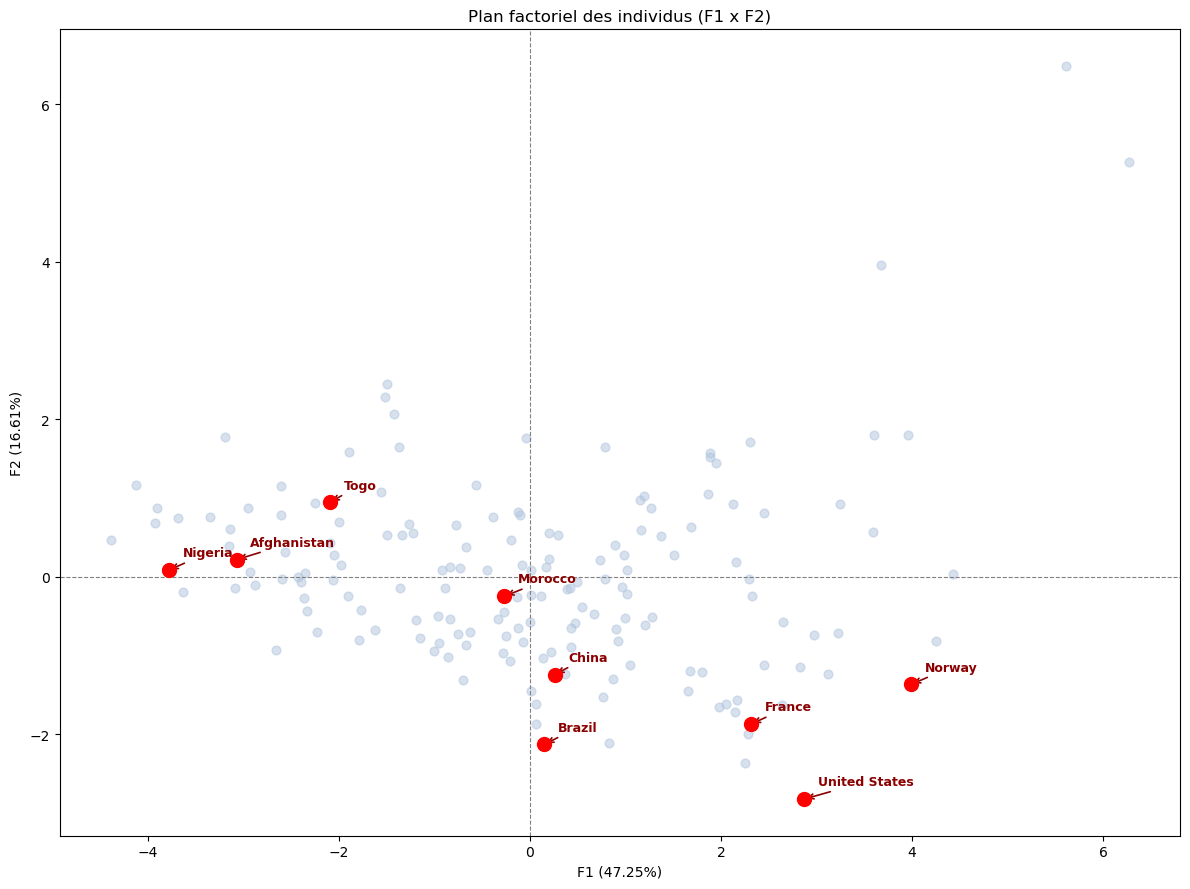

In [49]:
plt.figure(figsize=(12, 9))

# Tous les pays en gris discret
plt.scatter(composantes_df["F1"], composantes_df["F2"],
            color="lightsteelblue", alpha=0.5, s=40)

# Les pays importants en rouge et plus grands
pays_a_annoter = ["France", "United States", "China", "Nigeria",
                  "Afghanistan", "Norway", "Brazil", "Morocco", "Togo"]

for pays in pays_a_annoter:
    if pays in composantes_df.index:
        x = composantes_df.loc[pays, "F1"]
        y = composantes_df.loc[pays, "F2"]

        # Point rouge plus grand
        plt.scatter(x, y, color="red", s=100, zorder=5)

        # Nom du pays avec une flèche
        plt.annotate(pays, (x, y),
                     textcoords="offset points",
                     xytext=(10, 10),
                     fontsize=9,
                     fontweight="bold",
                     color="darkred",
                     arrowprops=dict(arrowstyle="->",
                                     color="darkred",
                                     lw=1.2))

plt.axhline(0, color="gray", linewidth=0.8, linestyle="--")
plt.axvline(0, color="gray", linewidth=0.8, linestyle="--")
plt.xlabel(f"F1 ({pct_expliquee[0]:.2f}%)")
plt.ylabel(f"F2 ({pct_expliquee[1]:.2f}%)")
plt.title("Plan factoriel des individus (F1 x F2)")
plt.tight_layout()
plt.show()

## Interpretation du plan factoriel (F1 x F2)

- Le plan F1 x F2 explique 63,86 % de l'inertie (F1 : 47,25 %, F2 : 16,61 %). C'est une synthese solide, mais pas exhaustive.
- Le sens des axes est arbitraire : ce sont les oppositions qui comptent.

**Axe F1 (developpement socio-economique et sanitaire)**
- F1 est positif avec `esperance_vie`, `revenu`, `pib_habitant` et negatif avec `mortalite_infantile` et `fecondite`.
- A droite : pays plus riches et en meilleure sante. A gauche : pays plus pauvres avec mortalite infantile et fecondite elevees.

**Axe F2 (ouverture commerciale)**
- F2 est porte surtout par `importations` et `exportations`.
- En haut : economies tres ouvertes. En bas : economies plus orientees vers le marche interieur.

**Lecture rapide des pays annotes**
- `Norway`, `France`, `United States` : F1 positif (developpement eleve), F2 negatif (ouverture plus moderee).
- `China`, `Brazil` : F1 proche de 0, F2 negatif (niveau intermediaire, ouverture plus faible).
- `Morocco`, `Togo`, `Nigeria`, `Afghanistan` : F1 negatif (moins developpes), F2 variable selon l'ouverture.

**A ne pas sur-interpreter sur F1 x F2**
- `inflation` et `depenses_sante` sont mal representees sur ce plan : a lire sur les axes suivants.



### Cercle des corrélations

In [50]:
# Corrélations variables-axes : r(x_j, F_k) = v_jk * sqrt(λ_k)
correlations = vecteurs_propres * np.sqrt(valeurs_propres)
corr_df = pd.DataFrame(
    correlations,
    index=numeric_cols,
    columns=[f"F{i+1}" for i in range(len(valeurs_propres))]
)
print("Corrélations variables-axes :")
print(corr_df.round(4))


Corrélations variables-axes :
                         F1      F2      F3      F4      F5      F6      F7  \
mortalite_infantile -0.8655  0.2544 -0.3019 -0.0539 -0.2048  0.0827  0.0261   
exportations         0.5610  0.7673  0.0868 -0.1037 -0.0143  0.1313 -0.2336   
depenses_sante       0.3836 -0.2604 -0.2282  0.7030 -0.4708  0.0607 -0.0750   
importations         0.4010  0.7958  0.1371  0.3529 -0.0451 -0.1407  0.1859   
revenu               0.8037  0.0185 -0.2772 -0.4254 -0.2011  0.0727  0.1018   
inflation           -0.2975 -0.0666  0.6766 -0.2274 -0.6253 -0.0253 -0.0016   
esperance_vie        0.8927 -0.2768  0.1712 -0.0032  0.1445 -0.1869 -0.1208   
fecondite           -0.8362  0.2194 -0.3498 -0.1103 -0.1620 -0.2389 -0.1325   
pib_habitant         0.7904 -0.0425 -0.3778 -0.2717 -0.3284 -0.0857  0.0287   

                         F8      F9  
mortalite_infantile -0.1149 -0.1536  
exportations        -0.0085  0.0136  
depenses_sante       0.0436 -0.0073  
importations         0.0055

###  Visualisation Cercle de corrélation 

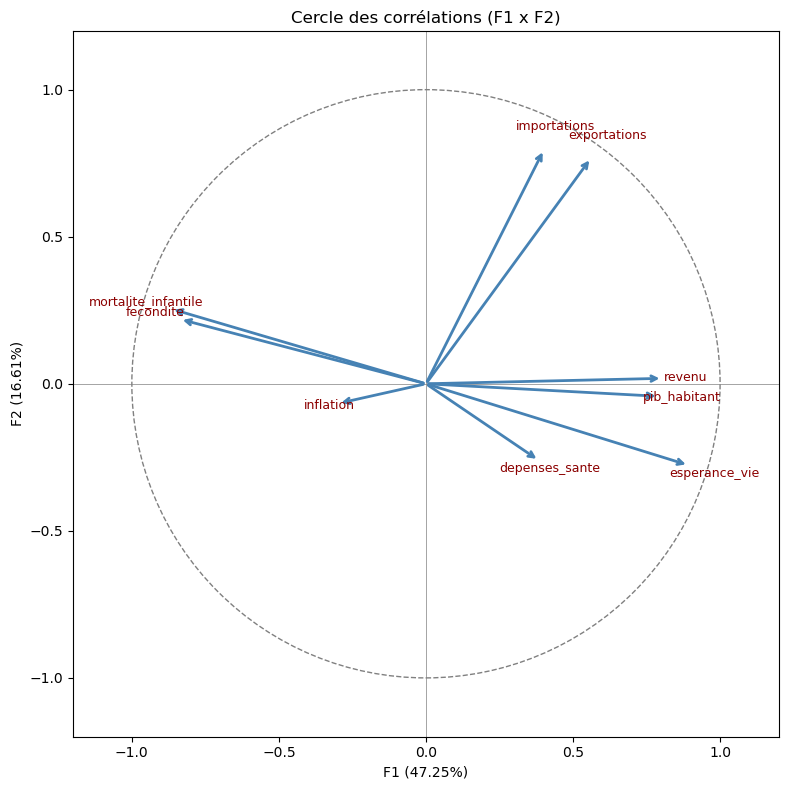

In [51]:
# Cercle des corrélations
fig, ax = plt.subplots(figsize=(8, 8))
cercle = plt.Circle((0, 0), 1, fill=False, color="gray", linestyle="--")
ax.add_patch(cercle)

for i, var in enumerate(numeric_cols):
    x = corr_df.loc[var, "F1"]
    y = corr_df.loc[var, "F2"]
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="steelblue", lw=2))
    ax.text(x * 1.1, y * 1.1, var, fontsize=9,
            ha="center", va="center", color="darkred")

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set_xlabel(f"F1 ({pct_expliquee[0]:.2f}%)")
ax.set_ylabel(f"F2 ({pct_expliquee[1]:.2f}%)")
ax.set_title("Cercle des corrélations (F1 x F2)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## Interprétation du cercle des corrélations

Les flèches proches indiquent des variables positivement corrélées ; les flèches opposées, des variables négativement corrélées. La mortalité infantile et la fécondité vont dans le même sens, tandis que l'espérance de vie leur est opposée. Le revenu et le PIB par habitant sont proches l'un de l'autre, de même que les exportations et les importations.

Les variables proches du cercle sont bien représentées dans le plan F1 × F2 ; celles plus proches du centre le sont moins. Ainsi, les dépenses de santé et l'inflation sont peu lisibles sur ce plan. Les angles doivent être interprétés avec prudence pour les variables mal représentées.


## Qualité de représentation

### Formule avec le cosinus

La qualité de représentation d'une variable $X_i$ sur un axe $F_j$ est donnée par :

$$\text{Qualité}(X_i, F_j) = \cos^2(\theta) = \frac{r_{ij}^2}{||X_i||^2}$$

où :
- $r_{ij}$ = corrélation entre la variable $X_i$ et l'axe $F_j$
- $||X_i||^2$ = somme des carrés de toutes les corrélations de la variable $X_i$



### Interprétation

- **Qualité proche de 1** = la variable est bien représentée sur cet axe (vecteur proche de l'axe)
- **Qualité proche de 0** = la variable est mal représentée (vecteur loin de l'axe)
- **Total ≈ 1** = la variable est bien représentée dans le plan factoriel

In [52]:
# Matrice des corrélations variables-axes
F = corr_df.values

# Norme au carré de chaque variable
norme2 = np.sum(F**2, axis=1)

# Qualité sur chaque axe
qualite = pd.DataFrame({
    "Qlté(F1)": (F[:,0]**2) / norme2,
    "Qlté(F2)": (F[:,1]**2) / norme2,
    "Total": np.sum(F[:,:2]**2, axis=1) / norme2
}, index=numeric_cols)

print("Qualité de représentation des variables")
print("=" * 60)
print(qualite.round(4))

Qualité de représentation des variables
                     Qlté(F1)  Qlté(F2)   Total
mortalite_infantile    0.7535    0.0651  0.8186
exportations           0.3166    0.5923  0.9089
depenses_sante         0.1480    0.0682  0.2162
importations           0.1617    0.6370  0.7988
revenu                 0.6498    0.0003  0.6501
inflation              0.0890    0.0045  0.0935
esperance_vie          0.8017    0.0771  0.8788
fecondite              0.7033    0.0484  0.7518
pib_habitant           0.6285    0.0018  0.6303


## Contribution des variables

### Formule

Contribution(X_i, F_k) = (r_ik^2 / lambda_k) * 100

ou : r_ik = correlation entre la variable X_i et l'axe F_k, et lambda_k est la valeur propre.

### Interpretation

- Pour chaque axe, la somme des contributions vaut 100%.
- Une variable avec une contribution elevee participe fortement a la definition de l'axe.
- On lit donc surtout les variables qui contribuent le plus sur F1 et F2.


In [53]:
# Contribution des variables aux axes
contrib = pd.DataFrame({
    'Contrib(F1)%': (corr_df['F1']**2 / valeurs_propres[0]) * 100,
    'Contrib(F2)%': (corr_df['F2']**2 / valeurs_propres[1]) * 100,
}, index=numeric_cols)

print('Contribution des variables aux axes (%)')
print('=' * 60)
print(contrib.round(2))

top_f1 = contrib['Contrib(F1)%'].sort_values(ascending=False)
top_f2 = contrib['Contrib(F2)%'].sort_values(ascending=False)
print('\nTop contributions F1:')
print(top_f1.round(2))
print('\nTop contributions F2:')
print(top_f2.round(2))


Contribution des variables aux axes (%)
                     Contrib(F1)%  Contrib(F2)%
mortalite_infantile         17.72          4.36
exportations                 7.45         39.62
depenses_sante               3.48          4.56
importations                 3.80         42.62
revenu                      15.28          0.02
inflation                    2.09          0.30
esperance_vie               18.85          5.16
fecondite                   16.54          3.24
pib_habitant                14.78          0.12

Top contributions F1:
esperance_vie          18.85
mortalite_infantile    17.72
fecondite              16.54
revenu                 15.28
pib_habitant           14.78
exportations            7.45
importations            3.80
depenses_sante          3.48
inflation               2.09
Name: Contrib(F1)%, dtype: float64

Top contributions F2:
importations           42.62
exportations           39.62
esperance_vie           5.16
depenses_sante          4.56
mortalite_infantile   

## Interprétation de la Qualité

| Qualité | Signification |
|---------|---|
| > 0.8 | Bien représentée |
| 0.5 — 0.8 | Moyennement représentée |
| < 0.5 | Mal représentée |

- **Total ≈ 1** : variable bien visible dans le plan F1×F2
- **Total < 0.5** : variable peu visible (liée à d'autres axes)

## Synthese des Interpretations

### Qualite de representation (plan F1 x F2)

| Categorie | Variables (Total) | Lecture rapide |
|---|---|---|
| Bien representees (> 0.8) | exportations (0.9089), esperance_vie (0.8788), mortalite_infantile (0.8186) | Tres bien visibles sur le plan F1 x F2 |
| Moyennement representees (0.5-0.8) | importations (0.7988), fecondite (0.7518), revenu (0.6501), pib_habitant (0.6303) | Interpretables, mais une partie de l'info est sur d'autres axes |
| Mal representees (< 0.5) | depenses_sante (0.2162), inflation (0.0935) | Peu visibles sur F1 x F2, a lire sur des axes suivants |

### Lecture par axe

| Axe | Variables les mieux portees (cos^2 eleves) |
|---|---|
| F1 | esperance_vie, mortalite_infantile, fecondite, revenu, pib_habitant |
| F2 | importations, exportations |


## Contribution des individus

### Formule

Contribution(Mi, Fk) = p_i * (c_ik^2 / lambda_k)

ou :
- p_i = 1/n (poids de chaque individu)
- c_ik = coordonnee de l'individu i sur l'axe k
- lambda_k = valeur propre de l'axe k


In [54]:
I = len(Xcr)
Pi = 1 / I

contr_F1 = Pi * (composantes_df["F1"] ** 2) / valeurs_propres[0]
contr_F2 = Pi * (composantes_df["F2"] ** 2) / valeurs_propres[1]

contr_plan = (valeurs_propres[0] * contr_F1 + valeurs_propres[1] * contr_F2) / (valeurs_propres[0] + valeurs_propres[1])

contrib_individus = pd.DataFrame({
    "Contr(Mi, F1)"      : contr_F1,
    "Contr(Mi, F2)"      : contr_F2,
    "Contr(Mi, (F1,F2))" : contr_plan
}, index=df["pays"].values)

print("Contribution des 5 premiers pays :")
print(contrib_individus.head(5).round(4))


Contribution des 5 premiers pays :
                     Contr(Mi, F1)  Contr(Mi, F2)  Contr(Mi, (F1,F2))
Afghanistan                 0.0132         0.0002              0.0098
Albania                     0.0003         0.0017              0.0006
Algeria                     0.0002         0.0011              0.0004
Angola                      0.0143         0.0125              0.0139
Antigua and Barbuda         0.0014         0.0000              0.0011
